In [111]:
import pickle
import sys

sys.path = [p for p in sys.path if "positron-python" not in p]

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import seaborn as sns
from sklearn.metrics import confusion_matrix

import myutils


In [112]:
workspace,experiment=myutils.workspace()
save = True

In [113]:
model_dir = experiment / "results/pred-with-fine-tuning" / 'pred_heroes-2026-10-25_172348' 
model_results = model_dir / 'results.pkl'
with open(model_results, 'rb') as f:
    model_results = pickle.load(f)
id2type = model_results['id_maps']

In [ ]:
run = "pred_scGPT_pancancer-2026-10-29_134407"
run_dir = experiment / f'results/pred-on-fine-tuned/{run}'
result_file = run_dir / 'results.pkl'
assert result_file.exists()
data_file = experiment / "data/heroes_pool8_scRNA_hvg.h5ad"
celltype_col = "consensus_celltype"
assert data_file.exists()

with open(result_file, 'rb') as f:
    results = pickle.load(f)
predictions = results['predictions']

adata = sc.read(data_file)
print(adata)
adata.obs["predictions"] = [id2type[p] for p in predictions]
sum(adata.obs[celltype_col] == adata.obs['predictions'])

AnnData object with n_obs × n_vars = 8813 × 3000
    obs: 'pool', 'assignment', 'celltype', 'seurat_clusters', 'Cohort', 'Entity', 'Fusion', 'Episode', 'PID', 'Location', 'barcode_sample', 'n_genes', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', '_scvi_batch', '_scvi_labels', 'leiden', 'X', 'final', 'consensus_celltype'
    var: 'n_cells', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    obsm: 'X_scVI', 'X_umap', '_scvi_extra_categorical_covs'
    obsp: 'connectivities', 'distances'
    layers: 'counts', 'scvi_normalized', None (.X)


1265

In [115]:
# adata = adata[adata.obs.consensus_celltype != 'Low Confidence']

from collections import Counter

Counter(predictions)

Counter({np.int64(1): 5743,
         np.int64(2): 1424,
         np.int64(3): 1383,
         np.int64(4): 261,
         np.int64(0): 2})

In [116]:
sc.pl.umap(
        adata,
        color=celltype_col,
        ncols=1,
        show=False
    )
_palette = dict(
    zip(
        adata.obs[celltype_col].cat.categories,
        adata.uns[f"{celltype_col}_colors"],
    )
)
plt.close()

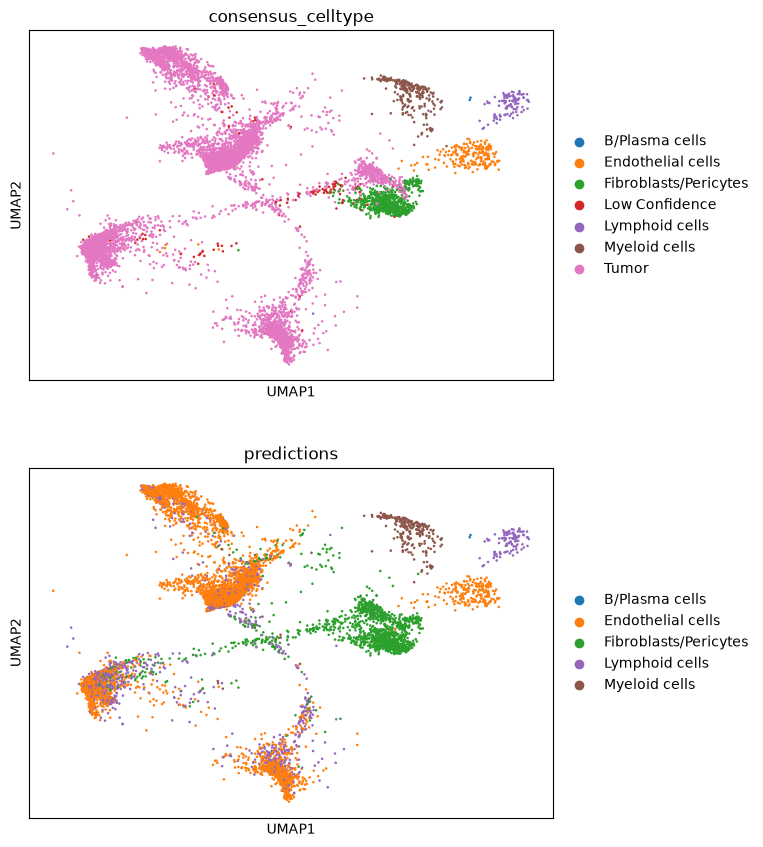

In [117]:
sc.pl.umap(
        adata,
        color=[celltype_col, "predictions"],
        ncols=1,
        palette=_palette,
        show=False,
    )
if save: plt.savefig(run_dir / "results.png", dpi=300, bbox_inches="tight")

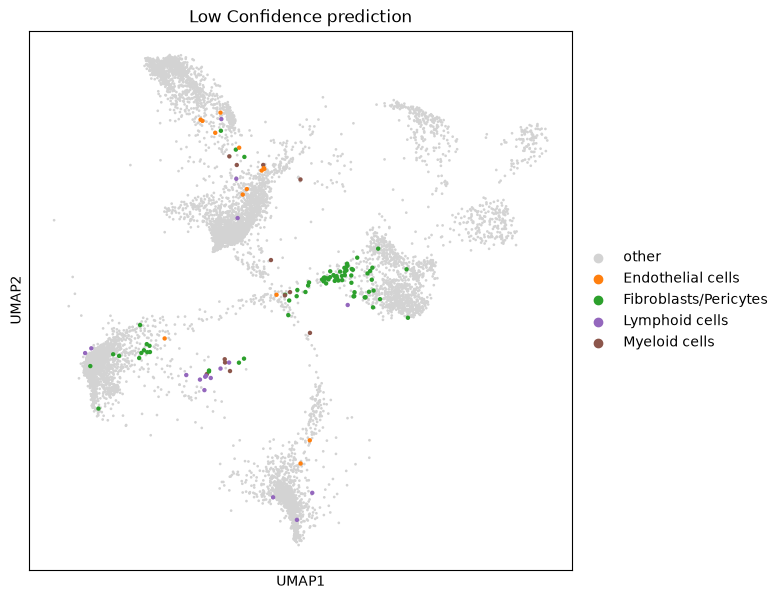

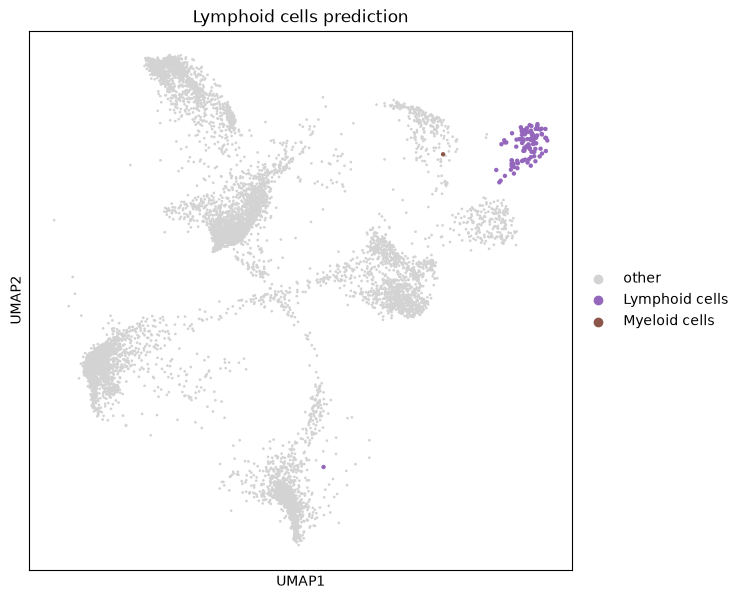

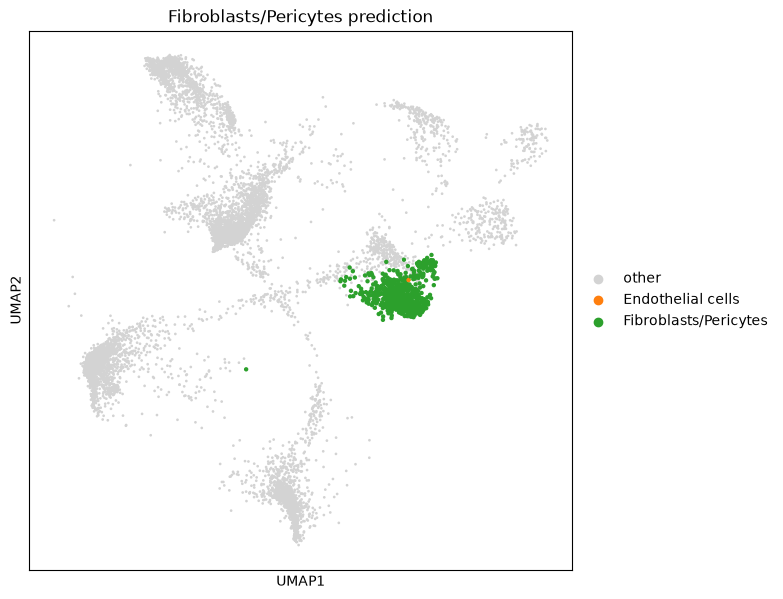

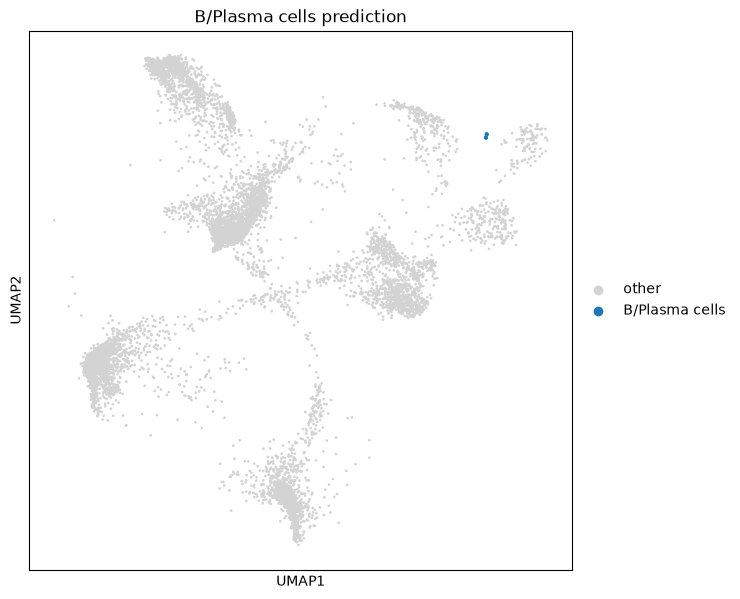

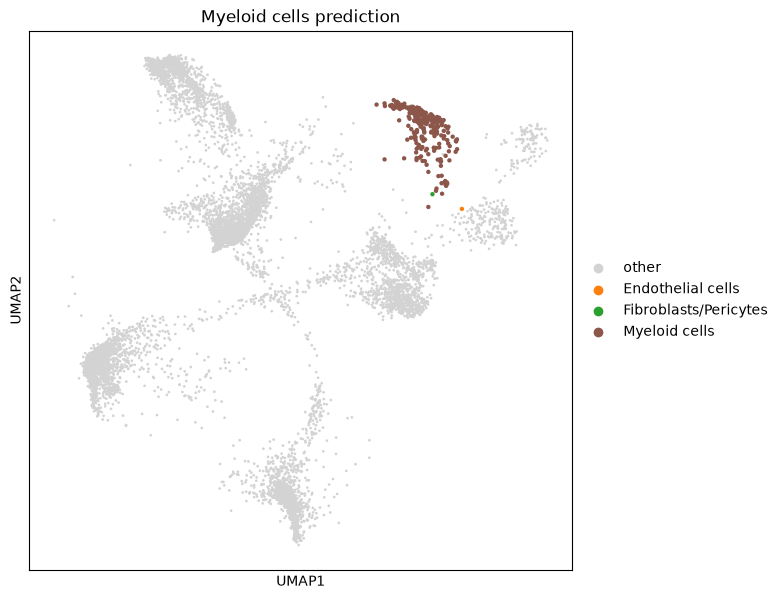

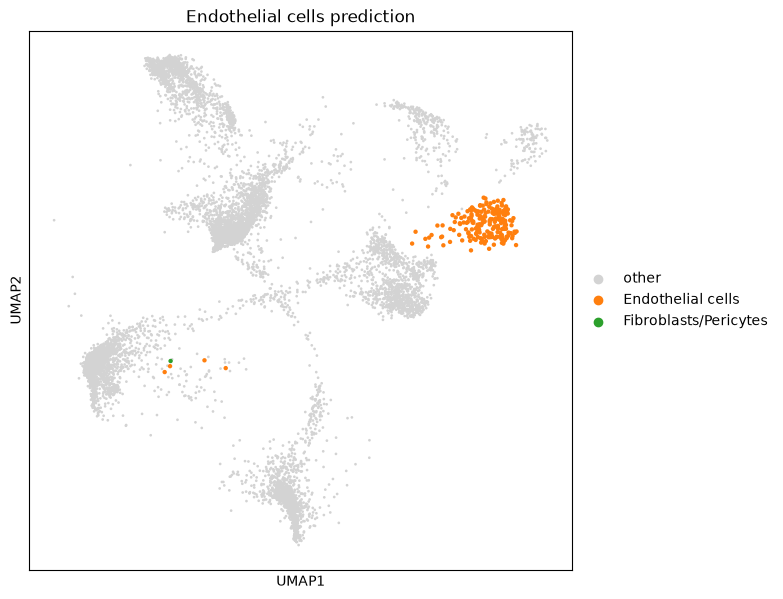

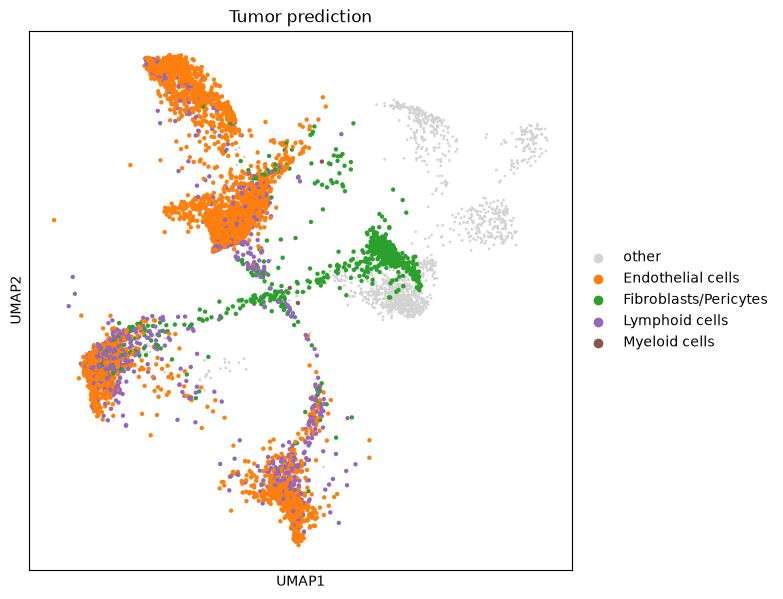

In [121]:
adata_plot = adata.copy()

myutils.inspect_prediction(adata_plot, 'Low Confidence', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)
myutils.inspect_prediction(adata_plot, 'Lymphoid cells', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)
myutils.inspect_prediction(adata_plot, 'Fibroblasts/Pericytes', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)
myutils.inspect_prediction(adata_plot, 'B/Plasma cells', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)
myutils.inspect_prediction(adata_plot, 'Myeloid cells', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)
myutils.inspect_prediction(adata_plot, 'Endothelial cells', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)
myutils.inspect_prediction(adata_plot, 'Tumor', palette=_palette, celltype_col="consensus_celltype", save_dir=run_dir)

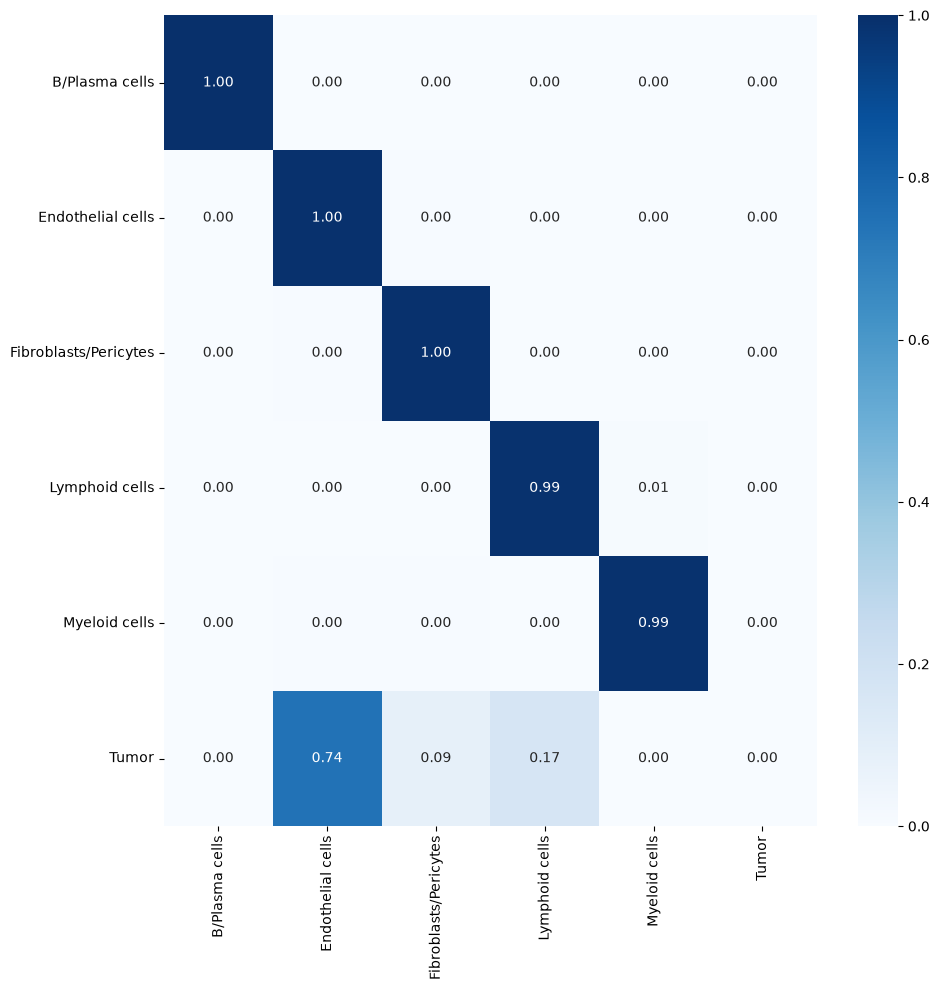

In [120]:
celltypes = [c for c in adata.obs[celltype_col].unique() if c in id2type.values()]
celltypes = [id2type[i] for i in range(len(celltypes))]
adata_wo_lowconf = adata[adata.obs.consensus_celltype != 'Low Confidence'].copy()
labels = adata_wo_lowconf.obs.consensus_celltype.tolist() 
predictions = adata_wo_lowconf.obs.predictions.tolist() 
cm = confusion_matrix(labels, predictions)
cm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
cm = pd.DataFrame(cm, index=celltypes[:cm.shape[0]], columns=celltypes[:cm.shape[0]])
plt.figure(figsize=(10, 10))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues")
plt.yticks(rotation=0)
plt.tight_layout()
if save: plt.savefig(run_dir / "confusion_matrix.png", dpi=300, )